# Facial expression recognition with CNN + MLP

Classify 48 x 48 grayscale images into seven FER2013 emotions. This baseline trains for 15 epochs on the original images.

In [1]:
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

cwd = Path.cwd()
candidates = (cwd / "BTL03", cwd, *cwd.parents)
project = next(path for path in candidates if (path / "4. Training Utilities" / "shared_training.py").is_file())
utility_dir = project / "4. Training Utilities"
sys.path.insert(0, str(utility_dir))
from shared_training import run_epoch

use_cuda = True
device = torch.device("cuda" if use_cuda and torch.cuda.is_available() else "cpu")
emotions = ("angry", "disgust", "fear", "happy", "sad", "surprise", "neutral")
num_classes = len(emotions)

## 1. Load FER2013

Read the two one-hot CSV files from the sibling Training Utilities folder. Each row contains 2,304 grayscale values followed by seven label values. PublicTest is used for validation and final evaluation.

In [2]:
def load_fer2013(csv_path):
    rows = np.loadtxt(csv_path, delimiter=",", dtype=np.float32, ndmin=2)
    images = np.ascontiguousarray(rows[:, :2304].reshape(-1, 1, 48, 48))
    labels = rows[:, 2304:2304 + num_classes].argmax(axis=1)
    return torch.from_numpy(images), torch.as_tensor(labels, dtype=torch.long)


x_training, y_training = load_fer2013(utility_dir / "fer2013_training_onehot.csv")
x_testing, y_testing = load_fer2013(utility_dir / "fer2013_publictest_onehot.csv")

print(f"Train: {len(x_training)} images")
print(f"PublicTest: {len(x_testing)} images")

Train: 28709 images
PublicTest: 3589 images


In [3]:
batch_size = 128
train_loader = DataLoader(TensorDataset(x_training, y_training), batch_size=batch_size, shuffle=True)
publictest_loader = DataLoader(TensorDataset(x_testing, y_testing), batch_size=batch_size)

## 2. Define the CNN + MLP

In [4]:
class EmotionCNN(nn.Sequential):
    def __init__(self, num_classes):
        super().__init__(
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout(0.25),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(128, 218, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(218, 218, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout(0.25),
            nn.Flatten(),
            nn.Linear(218 * 9 * 9, 1024),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(1024, num_classes),
        )

        # Match the default Keras kernel and bias initializers.
        for layer in self:
            if isinstance(layer, (nn.Conv2d, nn.Linear)):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)


model = EmotionCNN(num_classes).to(device)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

EmotionCNN(
  (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
  (3): ReLU()
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Dropout(p=0.25, inplace=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
  (9): ReLU()
  (10): Conv2d(128, 218, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU()
  (12): Conv2d(218, 218, kernel_size=(3, 3), stride=(1, 1))
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (15): Dropout(p=0.25, inplace=False)
  (16): Flatten(start_dim=1, end_dim=-1)
  (17): Linear(in_features=17658, out_features=1024, bias=True)
  (18): ReLU()
  (19): Dropout(p=0.5, inplace=False)
  (20): Linear(in_features=1024, out_features=7, bias=True)
)
Trainable parameters: 19,028,287


In [5]:
# Trace a single image through each layer to show the feature map shapes.
model.eval()
with torch.inference_mode():
    features = x_testing[:1].to(device)
    for layer in model:
        features = layer(features)
        print(f"{layer.__class__.__name__:12} {tuple(features.shape)}")

Conv2d       (1, 64, 48, 48)
ReLU         (1, 64, 48, 48)
Conv2d       (1, 64, 46, 46)
ReLU         (1, 64, 46, 46)
MaxPool2d    (1, 64, 23, 23)
Dropout      (1, 64, 23, 23)
Conv2d       (1, 128, 23, 23)
ReLU         (1, 128, 23, 23)
Conv2d       (1, 128, 21, 21)
ReLU         (1, 128, 21, 21)
Conv2d       (1, 218, 21, 21)
ReLU         (1, 218, 21, 21)
Conv2d       (1, 218, 19, 19)
ReLU         (1, 218, 19, 19)
MaxPool2d    (1, 218, 9, 9)
Dropout      (1, 218, 9, 9)
Flatten      (1, 17658)
Linear       (1, 1024)
ReLU         (1, 1024)
Dropout      (1, 1024)
Linear       (1, 7)


## 3. Train for 15 epochs

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, eps=1e-7)
epochs = 15
history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
starting_time = perf_counter()

for epoch in range(1, epochs + 1):
    train_metrics = run_epoch(model, train_loader, criterion, device, optimizer)
    val_metrics = run_epoch(model, publictest_loader, criterion, device)
    history["loss"].append(train_metrics["loss"])
    history["accuracy"].append(train_metrics["accuracy"])
    history["val_loss"].append(val_metrics["loss"])
    history["val_accuracy"].append(val_metrics["accuracy"])
    print(
        f"Epoch [{epoch}/{epochs}] - loss: {train_metrics['loss']:.4f} "
        f"- accuracy: {train_metrics['accuracy']:.2%} - val_loss: {val_metrics['loss']:.4f} "
        f"- val_accuracy: {val_metrics['accuracy']:.2%}"
    )

print(f"Training time: {(perf_counter() - starting_time) / 60:.2f} minutes")

Epoch [1/15] - loss: 2.3695 - accuracy: 23.65% - val_loss: 1.8018 - val_accuracy: 25.97%
Epoch [2/15] - loss: 1.6971 - accuracy: 32.69% - val_loss: 1.5480 - val_accuracy: 40.35%
Epoch [3/15] - loss: 1.5522 - accuracy: 40.23% - val_loss: 1.4316 - val_accuracy: 45.17%
Epoch [4/15] - loss: 1.4368 - accuracy: 44.72% - val_loss: 1.3514 - val_accuracy: 49.29%
Epoch [5/15] - loss: 1.3359 - accuracy: 49.24% - val_loss: 1.2712 - val_accuracy: 51.94%
Epoch [6/15] - loss: 1.2492 - accuracy: 52.83% - val_loss: 1.2386 - val_accuracy: 53.44%
Epoch [7/15] - loss: 1.1606 - accuracy: 56.88% - val_loss: 1.1930 - val_accuracy: 54.97%
Epoch [8/15] - loss: 1.0765 - accuracy: 59.91% - val_loss: 1.1760 - val_accuracy: 55.64%
Epoch [9/15] - loss: 0.9947 - accuracy: 63.41% - val_loss: 1.1381 - val_accuracy: 58.18%
Epoch [10/15] - loss: 0.8918 - accuracy: 67.29% - val_loss: 1.1406 - val_accuracy: 58.26%
Epoch [11/15] - loss: 0.7901 - accuracy: 71.52% - val_loss: 1.1234 - val_accuracy: 59.18%
Epoch [12/15] - los

## 4. Evaluate on PublicTest and predict one image

In [7]:
score = run_epoch(model, publictest_loader, criterion, device)
print("Test loss:", score["loss"])
print("Test accuracy:", score["accuracy"])

Test loss: 1.2802873681799951
Test accuracy: 0.5984954026191139


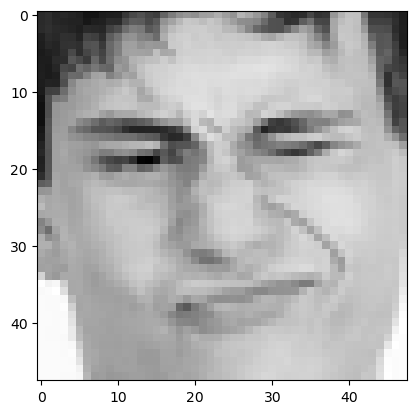

> Testing image index: 244
> True emotion: disgust
> Predicted emotion: disgust


In [8]:
image_index = np.random.randint(len(x_testing))
sample = x_testing[image_index]
true_label = y_testing[image_index].item()

model.eval()
with torch.inference_mode():
    predicted_label = model(sample.unsqueeze(0).to(device)).argmax(dim=1).item()

plt.imshow(sample.squeeze(0), cmap="gray")
plt.show()
print(f"> Testing image index: {image_index}")
print(f"> True emotion: {emotions[true_label]}")
print(f"> Predicted emotion: {emotions[predicted_label]}")